In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# to load the dataset
from datasets import load_dataset

In [37]:
emotion_dataset = load_dataset("dair-ai/emotion")
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']


In [38]:
label_name = emotion_dataset['train'].features['label'].names


In [39]:
df_train = pd.DataFrame(
    {
        "text": train_text,
        "label" : [label_name[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        "text": test_text,
        "label" : [label_name[i] for i in test_label]
    }
)

In [40]:
df_train.head()



,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [41]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


<Axes: xlabel='label', ylabel='count'>

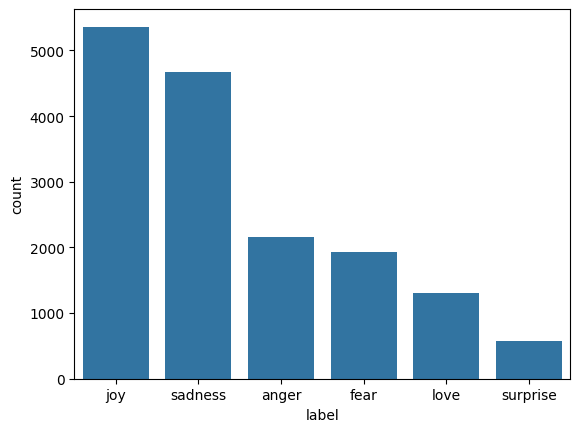

In [42]:
#EDA

sns.countplot(x = "label", data = df_train, order = df_train.label.value_counts().index)

In [43]:
# data preprocessing for NLP
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = "<unk>")
tokenizer.fit_on_texts(df_train.text)

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences, maxlen = 50, padding = "post", truncating = "post")
padded_test_sequences = pad_sequences(test_sequences, maxlen = 50, padding = "post", truncating = "post")

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequences.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


In [44]:
# calculating class weights
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = "balanced",
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

# early stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True
)

In [45]:
#phase 1 plain foundational model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    SimpleRNN(units= 128, return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

rnn_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
rnn_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.1600 - loss: 1.8952 - val_accuracy: 0.2495 - val_loss: 1.7688
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.1679 - loss: 1.8020 - val_accuracy: 0.1735 - val_loss: 1.7862
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 29ms/step - accuracy: 0.1696 - loss: 1.7819 - val_accuracy: 0.1190 - val_loss: 1.7880
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.1648 - loss: 1.7726 - val_accuracy: 0.1295 - val_loss: 1.7925
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2495 - loss: 1.7688
RNN Loss: 1.7688488960266113
RNN Accuracy: 0.24950000643730164


In [46]:
#LSTM MODEL
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    LSTM(units= 128, return_sequences = True),
    Dropout(0.5),
    LSTM(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

lstm_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
lstm_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 66s 125ms/step - accuracy: 0.1516 - loss: 1.7954 - val_accuracy: 0.2905 - val_loss: 1.7819
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 86ms/step - accuracy: 0.1509 - loss: 1.7937 - val_accuracy: 0.3495 - val_loss: 1.7760
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 92ms/step - accuracy: 0.1741 - loss: 1.7844 - val_accuracy: 0.1750 - val_loss: 1.7556
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 89s 107ms/step - accuracy: 0.2754 - loss: 1.6247 - val_accuracy: 0.3250 - val_loss: 1.5436
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 99ms/step - accuracy: 0.4454 - loss: 1.2306 - val_accuracy: 0.6450 - val_loss: 1.0179
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 77s 90ms/step - accuracy: 0.7030 - loss: 0.8323 - val_accuracy: 0.8505 - val_loss: 0.5970
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 45s 89ms/step - accuracy: 0.8524 - loss: 0.5063 - val_accuracy: 0.8720 - val_loss: 0.5189
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 89ms/step - accuracy: 0.8738 - loss: 0.4365 

In [47]:
#GRU MODEL
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    GRU(units= 128, return_sequences = True),
    Dropout(0.5),
    GRU(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

gru_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
gru_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 69ms/step - accuracy: 0.1507 - loss: 1.7970 - val_accuracy: 0.1110 - val_loss: 1.7969
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 68ms/step - accuracy: 0.1525 - loss: 1.7946 - val_accuracy: 0.0825 - val_loss: 1.7814
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 68ms/step - accuracy: 0.1483 - loss: 1.7952 - val_accuracy: 0.3500 - val_loss: 1.7796
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.1110 - loss: 1.7969
GRU Loss: 1.7969200611114502
GRU Accuracy: 0.11100000143051147


In [50]:
result_df = pd.DataFrame({
    "model": ["RNN","LSTM","GRYU"],
    "test_loss": [rnn_loss, lstm_loss, gru_loss],
    "test_accuracy": [rnn_accuracy, lstm_accuracy, gru_accuracy]
}).sort_values(by = "test_accuracy", ascending = False)
result_df

,model,test_loss,test_accuracy
1,LSTM,0.480111,0.8730
0,RNN,1.768849,0.2495
2,GRYU,1.796920,0.1110


In [51]:
# bidirectional GRU
# Left - right + right - left is called bidirectional GRU
from tensorflow.keras.layers import Bidirectional

Bigru = Sequential([
    Embedding(input_dim = max_words, output_dim = 300, input_length = 50),
    Bidirectional(GRU(128, return_sequences = True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

Bigru.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
Bigru.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 109s 205ms/step - accuracy: 0.5907 - loss: 1.0027 - val_accuracy: 0.8750 - val_loss: 0.3885
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 96s 193ms/step - accuracy: 0.9130 - loss: 0.2504 - val_accuracy: 0.9115 - val_loss: 0.2419
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 97s 194ms/step - accuracy: 0.9450 - loss: 0.1472 - val_accuracy: 0.9185 - val_loss: 0.2262
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 197ms/step - accuracy: 0.9591 - loss: 0.1131 - val_accuracy: 0.9215 - val_loss: 0.2177
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 95s 190ms/step - accuracy: 0.9657 - loss: 0.0935 - val_accuracy: 0.9230 - val_loss: 0.2274
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 148s 201ms/step - accuracy: 0.9726 - loss: 0.0767 - val_accuracy: 0.9195 - val_loss: 0.2545
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 97s 194ms/step - accuracy: 0.9800 - loss: 0.0584 - val_accuracy: 0.9145 - val_loss: 0.3000


In [52]:
BiGRU_loss, BiGRU_accuracy = Bigru.evaluate(padded_test_sequences, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9215 - loss: 0.2177
BiGRU Loss: 0.21774448454380035
BiGRU Accuracy: 0.921500027179718


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step


<Axes: >

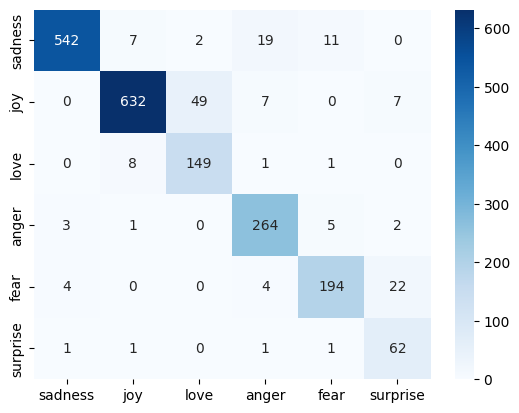

In [59]:
#evaluation and bias analysis
from sklearn.metrics import confusion_matrix
Bigru_predictions = np.argmax(Bigru.predict(padded_test_sequences),axis=1)

sns.heatmap(confusion_matrix(test_labels, Bigru_predictions),annot = True, fmt = "d", cmap = "Blues", xticklabels = label_name, yticklabels = label_name)


In [63]:
# final predictions
sample_texts = [
    "I can't believe how happy I am right now, this is amazing",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_seq = tokenizer.texts_to_sequences(sample_texts)
sample_pad = pad_sequences(sample_seq, maxlen = 50, padding = "post", truncating = "post")

sample_pred = np.argmax(Bigru.predict(sample_pad), axis = 1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_pred[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Text: I can't believe how happy I am right now, this is amazing
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [66]:
import os
import pickle
model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)
Bigru.save(os.path.join(model_dir, 'Bigru_model.keras'))

#save the tokenizer model
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)
